# Common Cold Detection — Breathiness Features

**Model:** Transformer Encoder + Focal Loss  
**Dataset:** URTIC (train / develop / test)  
**Metric:** UAR (Unweighted Average Recall = Balanced Accuracy)  
**Key fixes over baseline:**
- `librosa.lpc.lpc_to_lsf` bug fixed → proper LPC residual via `scipy.signal.lfilter`
- `pyin` computed **once per file** (not per frame) — 10–50× faster
- `state_dict` uses `copy.deepcopy` — previous shallow copy silently broke model restore
- UAR metric (not plain accuracy) — required for imbalanced cold dataset
- ROC + Youden's Index for optimal threshold
- SMOTE applied on train set to handle ~10:90 imbalance
- Transformer params aligned to paper (8 heads, d=256, dropout=0.4, lr=1e-4)

In [3]:
# ==========================================================
# CELL 1 — Install Libraries
# ==========================================================
!pip install librosa soundfile numpy pandas scikit-learn torch torchaudio \
    imbalanced-learn matplotlib seaborn tqdm scipy joblib


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
# ==========================================================
# CELL 2 — Imports & Seeds
# ==========================================================
import os, copy, warnings
import numpy as np
import pandas as pd
import librosa
import scipy.signal as signal
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    balanced_accuracy_score, roc_curve, auc
)
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import joblib
from concurrent.futures import ProcessPoolExecutor, as_completed
import multiprocessing

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device           : {device}")
print(f"CPU cores        : {multiprocessing.cpu_count()}")

Device           : cpu
CPU cores        : 12


In [5]:
# ==========================================================
# CELL 3 — Feature Extractor (FIXED & FAST)
# ==========================================================
class BreathinessFeatureExtractor:
    """
    Breathiness features for common cold detection.

    FIXES compared to original code:
    -------------------------------------------------------
    1. GNER: original called librosa.lpc.lpc_to_lsf — DOES NOT EXIST.
       Fixed: LPC residual computed via scipy.signal.lfilter (correct).
    2. PPQ / HE: original called librosa.pyin() inside per-frame loop
       → extremely slow. Fixed: pitch extracted ONCE per file.
    3. APQ: vectorised with np.convolve — no Python loop over frames.
    """

    def __init__(self, sr: int = 16000):
        self.sr           = sr
        self.frame_length = int(0.025 * sr)   # 25 ms
        self.hop_length   = int(0.010 * sr)   # 10 ms
        self.lpc_order    = 13

    # ----------------------------------------------------------
    def preprocess_audio(self, audio: np.ndarray) -> np.ndarray:
        """Pre-emphasis → energy-based silence removal → peak normalise."""
        audio = np.concatenate([[audio[0]], audio[1:] - 0.97 * audio[:-1]])

        frames  = librosa.util.frame(audio, frame_length=self.frame_length,
                                     hop_length=self.hop_length)
        energy  = np.sum(frames ** 2, axis=0)
        mask    = energy > np.mean(energy) * 0.1

        parts = [audio[i*self.hop_length : i*self.hop_length+self.frame_length]
                 for i, keep in enumerate(mask) if keep]
        if parts:
            audio = np.concatenate(parts)
        return audio / (np.max(np.abs(audio)) + 1e-10)

    # ----------------------------------------------------------
    def _get_pitch_track(self, audio):
        """Extract F0 + voiced flag ONCE per file (not per frame)."""
        f0, voiced, _ = librosa.pyin(
            audio,
            fmin=librosa.note_to_hz('C2'),
            fmax=librosa.note_to_hz('C7'),
            sr=self.sr,
            frame_length=self.frame_length,
            hop_length=self.hop_length,
            fill_na=np.nan
        )
        return f0, voiced

    # ----------------------------------------------------------
    def extract_ppq(self, f0, voiced, L=3) -> float:
        """Period Perturbation Quotient — FIX: uses pyin track."""
        valid_f0 = f0[voiced & ~np.isnan(f0)]
        if len(valid_f0) < L + 1:
            return 0.0
        periods  = self.sr / valid_f0
        mean_T   = np.mean(periods)
        if mean_T == 0:
            return 0.0
        N = len(periods)
        numerator = sum(abs(np.mean(periods[i:i+L]) - periods[i]) for i in range(N-L))
        return float(numerator / ((N-L) * mean_T))

    # ----------------------------------------------------------
    def extract_apq(self, audio: np.ndarray, L=7) -> float:
        """Amplitude Perturbation Quotient — vectorised."""
        frames     = librosa.util.frame(audio, frame_length=self.frame_length,
                                         hop_length=self.hop_length)
        amplitudes = np.max(np.abs(frames), axis=0).astype(float)
        if len(amplitudes) < L + 1:
            return 0.0
        mean_A = np.mean(amplitudes)
        if mean_A == 0:
            return 0.0
        smoothed = np.convolve(amplitudes, np.ones(L)/L, mode='valid')
        diff     = np.abs(smoothed[:-1] - amplitudes[:len(amplitudes)-L])
        return float(np.mean(diff) / mean_A)

    # ----------------------------------------------------------
    def extract_hnr(self, audio: np.ndarray) -> float:
        """Harmonic-to-Noise Ratio via autocorrelation."""
        ac   = np.correlate(audio, audio, mode='full')
        ac   = ac[len(ac)//2:]
        if ac[0] == 0:
            return 0.0
        max_v = ac[np.argmax(ac[1:]) + 1]
        r     = np.clip(max_v / ac[0], 1e-10, 1-1e-10)
        return float(10 * np.log10(r / (1 - r)))

    # ----------------------------------------------------------
    def extract_gner(self, audio: np.ndarray) -> float:
        """
        Glottal-to-Noise Excitation Ratio.

        FIX: Original called librosa.lpc.lpc_to_lsf which does NOT exist.
        Correct: compute LPC residual via scipy.signal.lfilter(lpc, [1], frame).
        """
        frames = librosa.util.frame(audio, frame_length=self.frame_length,
                                     hop_length=self.hop_length)
        gner_vals = []
        for frame in frames.T:
            try:
                lpc      = librosa.lpc(frame, order=self.lpc_order)
                residual = signal.lfilter(lpc, [1.0], frame)   # ← FIXED
                envelope = np.abs(signal.hilbert(residual))
                n        = len(envelope)
                energies = np.array([
                    np.sum(envelope[0    : n//8]**2),
                    np.sum(envelope[n//8 : n//4]**2),
                    np.sum(envelope[n//4 : n//2]**2),
                    np.sum(envelope[n//2 :     ]**2),
                ])
                total = energies.sum()
                if total > 0:
                    gner_vals.append(energies.max() / total)
            except Exception:
                continue
        return float(np.mean(gner_vals)) if gner_vals else 0.0

    # ----------------------------------------------------------
    def extract_harmonic_energy(self, audio, f0, voiced) -> float:
        """H1/H2 ratio — FIX: pitch extracted once, not per frame."""
        valid_f0 = f0[voiced & ~np.isnan(f0)]
        if len(valid_f0) == 0:
            return 0.0
        med_f0  = float(np.median(valid_f0))
        if med_f0 < 50:
            return 0.0
        N   = 2048
        mag = np.abs(np.fft.rfft(audio, n=N))

        def peak(freq):
            b  = int(round(freq * N / self.sr))
            r  = max(1, int(0.05 * b))
            lo, hi = max(0, b-r), min(len(mag), b+r+1)
            return float(mag[lo:hi].max()) if lo < hi else 0.0

        h1, h2 = peak(med_f0), peak(2*med_f0)
        return float(h1 / h2) if h2 > 0 else 0.0

    # ----------------------------------------------------------
    def extract_all_features(self, audio_path: str):
        """Extract all features; returns dict or None on failure."""
        try:
            audio, _ = librosa.load(audio_path, sr=self.sr, mono=True)
            audio    = self.preprocess_audio(audio)
            if len(audio) < self.frame_length * 2:
                return None

            f0, voiced = self._get_pitch_track(audio)   # computed ONCE

            feats = {
                'PPQ' : self.extract_ppq(f0, voiced),
                'APQ' : self.extract_apq(audio),
                'HNR' : self.extract_hnr(audio),
                'GNE' : self.extract_gner(audio),
                'HE'  : self.extract_harmonic_energy(audio, f0, voiced),
            }

            # Supporting acoustic features
            feats['ZCR']               = float(np.mean(librosa.feature.zero_crossing_rate(audio)))
            feats['spectral_centroid'] = float(np.mean(librosa.feature.spectral_centroid(y=audio, sr=self.sr)))
            feats['spectral_rolloff']  = float(np.mean(librosa.feature.spectral_rolloff(y=audio, sr=self.sr)))
            feats['spectral_bandwidth']= float(np.mean(librosa.feature.spectral_bandwidth(y=audio, sr=self.sr)))
            feats['rms_energy']        = float(np.mean(librosa.feature.rms(y=audio)))

            mfcc = librosa.feature.mfcc(y=audio, sr=self.sr, n_mfcc=13)
            for i, v in enumerate(np.mean(mfcc, axis=1)):
                feats[f'mfcc_{i+1}'] = float(v)
            for i, v in enumerate(np.std(mfcc, axis=1)):
                feats[f'mfcc_std_{i+1}'] = float(v)

            # Pitch statistics
            valid_f0 = f0[voiced & ~np.isnan(f0)]
            feats['voiced_fraction'] = float(np.mean(voiced)) if len(voiced)>0 else 0.0
            feats['f0_mean']  = float(np.mean(valid_f0))   if len(valid_f0)>0 else 0.0
            feats['f0_std']   = float(np.std(valid_f0))    if len(valid_f0)>0 else 0.0
            feats['jitter_abs']= float(np.mean(np.abs(np.diff(valid_f0)))) if len(valid_f0)>1 else 0.0

            return feats
        except Exception as e:
            print(f"  [WARN] {os.path.basename(audio_path)}: {e}")
            return None

In [6]:
# ==========================================================
# CELL 4 — Dataset Loading
# ==========================================================
def load_dataset(root_dir: str) -> pd.DataFrame:
    rows = []
    for split in ['train', 'test', 'develop']:
        for label in ['cold', 'noncold']:
            folder = os.path.join(root_dir, split, label)
            if not os.path.isdir(folder):
                continue
            for fn in os.listdir(folder):
                if fn.lower().endswith('.wav'):
                    rows.append({'path': os.path.join(folder, fn),
                                 'label': label, 'split': split})
    return pd.DataFrame(rows)

# ── UPDATE THIS PATH ──────────────────────────────────────────
DATASET_PATH = r"E:\Final Year Project\dataset\URTIC"

df = load_dataset(DATASET_PATH)
print(f"Total samples       : {len(df)}")
print(f"\nClass distribution:\n{df['label'].value_counts()}")
print(f"\nSplit distribution:\n{df['split'].value_counts()}")
cold_n    = (df['label']=='cold').sum()
noncold_n = (df['label']=='noncold').sum()
print(f"\nImbalance  cold:noncold = 1:{noncold_n//max(cold_n,1)}")

Total samples       : 28647

Class distribution:
label
noncold    25772
cold        2875
Name: count, dtype: int64

Split distribution:
split
develop    9596
test       9549
train      9502
Name: count, dtype: int64

Imbalance  cold:noncold = 1:8


In [7]:
# ============================================
# CELL 5: Ultra-Fast Feature Extraction with Batch Processing
# ============================================
import pickle
import hashlib
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

class UltraFastFeatureExtractor:
    """Ultra-fast feature extraction optimized for large datasets"""
    
    def __init__(self, sr=16000, duration=3.0):  # Reduced duration for speed
        self.sr = sr
        self.duration = duration
        
    def extract_features_batch(self, audio_paths):
        """Extract features for multiple files at once using batch processing"""
        features_batch = []
        
        for audio_path in audio_paths:
            try:
                # Load audio with minimal processing
                audio, _ = librosa.load(audio_path, sr=self.sr, duration=self.duration, 
                                       res_type='kaiser_fast')
                
                if len(audio) < self.sr * 0.5:  # Less than 0.5 seconds
                    features_batch.append(None)
                    continue
                
                # Extract features using optimized methods
                features = {}
                
                # 1. Fast MFCC (most discriminative for voice quality)
                mfccs = librosa.feature.mfcc(y=audio, sr=self.sr, n_mfcc=13, 
                                            n_fft=512, hop_length=128)
                mfcc_means = np.mean(mfccs, axis=1)
                for i in range(13):
                    features[f'mfcc_{i+1}'] = mfcc_means[i]
                
                # 2. Spectral features
                spectral_centroids = librosa.feature.spectral_centroid(y=audio, sr=self.sr, 
                                                                       n_fft=512, hop_length=128)[0]
                spectral_rolloff = librosa.feature.spectral_rolloff(y=audio, sr=self.sr, 
                                                                    n_fft=512, hop_length=128)[0]
                zero_crossings = librosa.feature.zero_crossing_rate(audio, hop_length=128)[0]
                rms = librosa.feature.rms(y=audio, hop_length=128)[0]
                
                features['spectral_centroid'] = np.mean(spectral_centroids)
                features['spectral_rolloff'] = np.mean(spectral_rolloff)
                features['zcr'] = np.mean(zero_crossings)
                features['rms'] = np.mean(rms)
                
                # 3. Chroma features (good for pitch-related features)
                chroma = librosa.feature.chroma_stft(y=audio, sr=self.sr, n_fft=512, hop_length=128)
                features['chroma_std'] = np.std(chroma)
                features['chroma_mean'] = np.mean(chroma)
                
                # 4. Harmonic features (for breathiness)
                harmonic, percussive = librosa.effects.hpss(audio)
                harmonic_energy = np.sum(harmonic**2)
                percussive_energy = np.sum(percussive**2)
                total_energy = harmonic_energy + percussive_energy + 1e-10
                features['harmonic_ratio'] = harmonic_energy / total_energy
                
                # 5. Simplified breathiness features
                # Use spectral flatness as proxy for breathiness
                spectral_flatness = librosa.feature.spectral_flatness(y=audio, n_fft=512, hop_length=128)[0]
                features['spectral_flatness'] = np.mean(spectral_flatness)
                
                # 6. Pitch-based features (simplified)
                pitches, magnitudes = librosa.piptrack(y=audio, sr=self.sr, 
                                                       fmin=50, fmax=300, 
                                                       n_fft=512, hop_length=128)
                pitch_values = pitches[pitches > 0]
                if len(pitch_values) > 0:
                    features['pitch_mean'] = np.mean(pitch_values)
                    features['pitch_std'] = np.std(pitch_values)
                    features['pitch_range'] = np.ptp(pitch_values)
                else:
                    features['pitch_mean'] = features['pitch_std'] = features['pitch_range'] = 0.0
                
                # 7. Formants (for voice quality)
                try:
                    # Simple formant estimation using LPC
                    lpc = librosa.lpc(audio, order=12)
                    roots = np.roots(lpc)
                    roots = roots[np.imag(roots) > 0]
                    angles = np.arctan2(np.imag(roots), np.real(roots))
                    freqs = angles * (self.sr / (2 * np.pi))
                    formants = freqs[(freqs > 50) & (freqs < 4000)]
                    if len(formants) >= 3:
                        features['formant_1'] = formants[0]
                        features['formant_2'] = formants[1]
                        features['formant_3'] = formants[2] if len(formants) > 2 else formants[1]
                    else:
                        features['formant_1'] = features['formant_2'] = features['formant_3'] = 0.0
                except:
                    features['formant_1'] = features['formant_2'] = features['formant_3'] = 0.0
                
                features_batch.append(features)
                
            except Exception as e:
                features_batch.append(None)
                
        return features_batch

class SimpleCachedExtractor:
    """Simpler caching without complex pickling issues"""
    
    def __init__(self, cache_dir='feature_cache'):
        self.cache_dir = Path(cache_dir)
        self.cache_dir.mkdir(exist_ok=True)
        self.extractor = UltraFastFeatureExtractor()
        
    def extract_features_simple(self, audio_path):
        """Simple extraction with file-based caching"""
        # Create cache filename from path
        cache_name = Path(audio_path).stem + '.npy'
        cache_path = self.cache_dir / cache_name
        
        # Try to load from cache
        if cache_path.exists():
            try:
                return np.load(cache_path, allow_pickle=True).item()
            except:
                pass
        
        # Extract features
        features = self.extractor.extract_features_batch([audio_path])[0]
        
        # Save to cache if successful
        if features is not None:
            try:
                np.save(cache_path, features)
            except:
                pass
        
        return features

def extract_features_fast(df, batch_size=100, use_cache=True):
    """
    Ultra-fast feature extraction using numpy arrays and batch processing
    """
    features_list = []
    labels = []
    splits = []
    failed_files = []
    
    if use_cache:
        extractor = SimpleCachedExtractor()
    else:
        extractor = UltraFastFeatureExtractor()
    
    total_files = len(df)
    print(f"Processing {total_files} files...")
    
    # Process in batches
    for batch_start in tqdm(range(0, total_files, batch_size), 
                           desc="Processing batches"):
        batch_end = min(batch_start + batch_size, total_files)
        batch_df = df.iloc[batch_start:batch_end]
        
        # Extract features for batch
        if use_cache:
            for _, row in batch_df.iterrows():
                try:
                    features = extractor.extract_features_simple(row['path'])
                    if features is not None:
                        features_list.append(features)
                        labels.append(row['label'])
                        splits.append(row['split'])
                    else:
                        failed_files.append(row['path'])
                except Exception as e:
                    failed_files.append(row['path'])
        else:
            # Batch extraction
            audio_paths = batch_df['path'].tolist()
            batch_features = extractor.extract_features_batch(audio_paths)
            
            for i, features in enumerate(batch_features):
                if features is not None:
                    features_list.append(features)
                    labels.append(batch_df.iloc[i]['label'])
                    splits.append(batch_df.iloc[i]['split'])
                else:
                    failed_files.append(batch_df.iloc[i]['path'])
    
    if len(features_list) == 0:
        raise ValueError("No files were successfully processed!")
    
    # Convert to numpy arrays
    feature_names = list(features_list[0].keys())
    X = np.array([[f.get(k, 0.0) for k in feature_names] for f in features_list])
    
    return X, np.array(labels), np.array(splits), feature_names, failed_files

# Run fast extraction
print("Starting ultra-fast feature extraction...")
print("This may take 30-60 minutes for 28,647 files...")

X_all, y_all, splits_all, feature_names, failed_files = extract_features_fast(
    df, 
    batch_size=200,  # Larger batch size for speed
    use_cache=True
)

print(f"\n✅ Successfully processed: {len(X_all)} files")
print(f"⚠️ Failed to process: {len(failed_files)} files")
print(f"Feature dimension: {X_all.shape[1]}")

# Create masks
mask_train = splits_all == 'train'
mask_test = splits_all == 'test'
mask_dev = splits_all == 'develop'

X_train, y_train = X_all[mask_train], y_all[mask_train]
X_test, y_test = X_all[mask_test], y_all[mask_test]
X_dev, y_dev = X_all[mask_dev], y_all[mask_dev]

print(f"\n📊 Dataset Statistics:")
print(f"Train: {len(X_train)} (cold: {np.sum(y_train=='cold')}, noncold: {np.sum(y_train=='noncold')})")
print(f"Test: {len(X_test)} (cold: {np.sum(y_test=='cold')}, noncold: {np.sum(y_test=='noncold')})")
print(f"Dev: {len(X_dev)} (cold: {np.sum(y_dev=='cold')}, noncold: {np.sum(y_dev=='noncold')})")

# Calculate class imbalance ratio
cold_ratio = np.sum(y_train == 'cold') / len(y_train)
print(f"\n⚠️ Class Imbalance: Cold samples are only {cold_ratio:.2%} of training data")

# Save processed features for later use
print("\n💾 Saving processed features...")
np.savez_compressed('processed_features.npz',
                    X_train=X_train, y_train=y_train,
                    X_test=X_test, y_test=y_test,
                    X_dev=X_dev, y_dev=y_dev,
                    feature_names=feature_names)

print("Features saved to 'processed_features.npz'")

# Optional: Quick verification
print("\n🔍 Feature Sample:")
sample_features = {name: X_train[0][i] for i, name in enumerate(feature_names[:10])}
for name, value in sample_features.items():
    print(f"  {name}: {value:.4f}")

Starting ultra-fast feature extraction...
This may take 30-60 minutes for 28,647 files...
Processing 28647 files...


Processing batches: 100%|██████████| 144/144 [10:45:31<00:00, 268.97s/it]   



✅ Successfully processed: 28646 files
⚠️ Failed to process: 1 files
Feature dimension: 27

📊 Dataset Statistics:
Train: 9502 (cold: 970, noncold: 8532)
Test: 9549 (cold: 894, noncold: 8655)
Dev: 9595 (cold: 1011, noncold: 8584)

⚠️ Class Imbalance: Cold samples are only 10.21% of training data

💾 Saving processed features...
Features saved to 'processed_features.npz'

🔍 Feature Sample:
  mfcc_1: -306.3564
  mfcc_2: 99.7421
  mfcc_3: -27.3923
  mfcc_4: 20.4107
  mfcc_5: -17.7386
  mfcc_6: -2.9108
  mfcc_7: -19.4485
  mfcc_8: -10.4993
  mfcc_9: -9.3952
  mfcc_10: -7.0639


In [17]:
# ============================================
# CELL 5: Ultra-Fast Feature Extraction + SMART CACHE (FINAL)
# ============================================

import os
import numpy as np

CACHE_FILE = "processed_features.npz"

# ==========================================================
# ✅ LOAD IF EXISTS
# ==========================================================
if os.path.exists(CACHE_FILE):
    print("⚡ Loading preprocessed dataset...")

    data = np.load(CACHE_FILE, allow_pickle=True)

    # ✅ Case 1: NEW FORMAT (already has eval)
    if 'X_eval' in data:
        print("✅ Found updated dataset format (train + eval)")

        X_train = data['X_train']
        y_train = data['y_train']
        X_eval  = data['X_eval']
        y_eval  = data['y_eval']
        feature_names = data['feature_names']

    # ✅ Case 2: OLD FORMAT → CREATE EVAL (dev + test)
    else:
        print("⚠️ Old dataset format detected → creating eval set (dev + test)")

        X_train = data['X_train']
        y_train = data['y_train']

        X_dev = data['X_dev']
        y_dev = data['y_dev']

        X_test = data['X_test']
        y_test = data['y_test']

        # 🔥 CONCATENATION (your choice)
        X_eval = np.concatenate([X_dev, X_test], axis=0)
        y_eval = np.concatenate([y_dev, y_test], axis=0)

        feature_names = data['feature_names']

        # ✅ SAVE UPDATED VERSION (one-time upgrade)
        print("💾 Updating saved dataset to new format...")
        np.savez_compressed(
            CACHE_FILE,
            X_train=X_train, y_train=y_train,
            X_eval=X_eval,   y_eval=y_eval,
            feature_names=feature_names
        )

        print("✅ Dataset upgraded — next run will be instant ⚡")

    print(f"\n📊 Dataset Loaded:")
    print(f"Train: {len(X_train)}")
    print(f"Eval (dev+test): {len(X_eval)}")


# ==========================================================
# ❌ FIRST RUN (NO CACHE FOUND)
# ==========================================================
else:
    print("⏳ First run — extracting features (this will take time)...")

    X_all, y_all, splits_all, feature_names, failed_files = extract_features_fast(
        df,
        batch_size=512,   # 🔥 increased for speed
        use_cache=True
    )

    print(f"\n✅ Successfully processed: {len(X_all)} files")

    # ✅ New split logic
    mask_train = splits_all == 'train'
    mask_eval  = (splits_all == 'test') | (splits_all == 'develop')

    X_train, y_train = X_all[mask_train], y_all[mask_train]
    X_eval,  y_eval  = X_all[mask_eval],  y_all[mask_eval]

    print(f"\n📊 Dataset Split:")
    print(f"Train: {len(X_train)}")
    print(f"Eval (dev+test): {len(X_eval)}")

    # ✅ SAVE
    print("\n💾 Saving dataset (one-time only)...")
    np.savez_compressed(
        CACHE_FILE,
        X_train=X_train, y_train=y_train,
        X_eval=X_eval,   y_eval=y_eval,
        feature_names=feature_names
    )

    print("✅ Saved! Next run will be instant ⚡")

⚡ Loading preprocessed dataset...
⚠️ Old dataset format detected → creating eval set (dev + test)
💾 Updating saved dataset to new format...
✅ Dataset upgraded — next run will be instant ⚡

📊 Dataset Loaded:
Train: 9502
Eval (dev+test): 19144


In [22]:
# ==========================================================
# CELL 6 — Preprocessing + SMOTE + DataLoaders (UPDATED)
# ==========================================================

from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE

# ✅ Safety
assert 'X_train' in globals(), "Run Cell 5 first"
assert 'X_eval' in globals(), "Eval set missing"

# ── Label Encoding ─────────────────────────────────────────
le = LabelEncoder()

y_train = np.array(y_train).astype(str)
y_eval  = np.array(y_eval).astype(str)

y_train_enc = le.fit_transform(y_train)
y_eval_enc  = le.transform(y_eval)

print(f"Class mapping: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# ── Scaling ────────────────────────────────────────────────
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_eval_s  = scaler.transform(X_eval)

# ── SMOTE ─────────────────────────────────────────────────
print(f"Before SMOTE: {dict(zip(*np.unique(y_train_enc, return_counts=True)))}")

smote = SMOTE(random_state=SEED, k_neighbors=5)
X_train_sm, y_train_sm = smote.fit_resample(X_train_s, y_train_enc)

print(f"After SMOTE: {dict(zip(*np.unique(y_train_sm, return_counts=True)))}")


# ── Dataset Class ─────────────────────────────────────────
class TabularDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.FloatTensor(X)
        self.y = torch.LongTensor(y)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]


# ── DataLoaders ───────────────────────────────────────────
BATCH_SIZE = 256

train_loader = DataLoader(
    TabularDataset(X_train_sm, y_train_sm),
    batch_size=BATCH_SIZE,
    shuffle=True
)

eval_loader = DataLoader(
    TabularDataset(X_eval_s, y_eval_enc),
    batch_size=BATCH_SIZE,
    shuffle=False
)

print(f"\nTrain batches={len(train_loader)}, Eval={len(eval_loader)}")

Class mapping: {np.str_('cold'): np.int64(0), np.str_('noncold'): np.int64(1)}
Before SMOTE: {np.int64(0): np.int64(970), np.int64(1): np.int64(8532)}
After SMOTE: {np.int64(0): np.int64(8532), np.int64(1): np.int64(8532)}

Train batches=67, Eval=75


In [23]:
# ==========================================================
# CELL 7 — Focal Loss + Transformer (paper-aligned)
# ==========================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# ── Focal Loss ───────────────────────────────────────────────
class FocalLoss(nn.Module):
    """FL(p_t) = -α (1-p_t)^γ log(p_t). Paper: α=1, γ=2."""
    def __init__(self, alpha=1.0, gamma=2.0):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits, targets):
        ce_loss = F.cross_entropy(logits, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        loss = self.alpha * (1 - pt) ** self.gamma * ce_loss
        return loss.mean()


# ── Positional Encoding ──────────────────────────────────────
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout=0.1, max_len=512):
        super().__init__(); self.drop = nn.Dropout(dropout)
        pe  = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len).float().unsqueeze(1)
        div = torch.exp(torch.arange(0,d_model,2).float() * (-np.log(10000.0)/d_model))
        pe[:,0::2] = torch.sin(pos*div); pe[:,1::2] = torch.cos(pos*div)
        self.register_buffer('pe', pe.unsqueeze(0))
    def forward(self, x):
        return self.drop(x + self.pe[:, :x.size(1)])


# ── Transformer Classifier ───────────────────────────────────
class TransformerClassifier(nn.Module):
    """
    Paper-aligned architecture:
      nhead=8, d_model=256, dim_feedforward=256, dropout=0.4
      Adam lr=0.0001, batch=256, focal loss
    FIX from original: Pre-LN (norm_first=True) for stable training.
    FIX from original: deepcopy used in training loop (not here but in trainer).
    """
    def __init__(self, input_dim, num_classes, d_model=256, nhead=8,
                 num_layers=2, dim_feedforward=256, dropout=0.4):
        super().__init__()
        self.proj   = nn.Linear(input_dim, d_model)
        self.pe     = PositionalEncoding(d_model, dropout)
        enc_layer   = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_feedforward,
            dropout=dropout, batch_first=True, norm_first=True)
        self.enc    = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
        self.head   = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, d_model//2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(d_model//2, num_classes))

    def forward(self, x):
        x = self.proj(x.unsqueeze(1))   # (B,1,d)
        x = self.pe(x)
        x = self.enc(x)
        return self.head(x.mean(dim=1))


input_dim   = X_train.shape[1]
num_classes = len(le.classes_)

model     = TransformerClassifier(input_dim, num_classes).to(device)
criterion = FocalLoss(alpha=1.0, gamma=2.0)
optimizer = optim.Adam(model.parameters(), lr=1e-4)        # paper: 0.0001
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=7)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model on {device} | params={total_params:,} | input_dim={input_dim} | classes={num_classes}")
print(model)

Model on cpu | params=832,386 | input_dim=27 | classes=2
TransformerClassifier(
  (proj): Linear(in_features=27, out_features=256, bias=True)
  (pe): PositionalEncoding(
    (drop): Dropout(p=0.4, inplace=False)
  )
  (enc): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
        )
        (linear1): Linear(in_features=256, out_features=256, bias=True)
        (dropout): Dropout(p=0.4, inplace=False)
        (linear2): Linear(in_features=256, out_features=256, bias=True)
        (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.4, inplace=False)
        (dropout2): Dropout(p=0.4, inplace=False)
      )
    )
  )
  (head): Sequential(
    (0): LayerNorm((256,), eps=1e-05, elementwise_affine=True

In [24]:
# ==========================================================
# CELL 8 — UAR Metric & Evaluation Helper
# ==========================================================
def compute_uar(y_true, y_pred) -> float:
    """UAR = balanced accuracy (mean per-class recall). Paper's primary metric."""
    return float(balanced_accuracy_score(y_true, y_pred) * 100)

def evaluate_loader(model, loader):
    """Returns (y_true, y_pred, y_prob_class1)."""
    model.eval()
    all_y, all_p, all_pr = [], [], []
    with torch.no_grad():
        for xb, yb in loader:
            out = model(xb.to(device))
            p   = torch.softmax(out, dim=1).cpu().numpy()
            all_y.extend(yb.numpy())
            all_p.extend(np.argmax(p, axis=1))
            all_pr.extend(p[:, 1])
    return np.array(all_y), np.array(all_p), np.array(all_pr)

In [25]:
# ==========================================================
# CELL 9 — Training Function (FIXED early-stop + deepcopy)
# ==========================================================
def train_model(model, train_loader, val_loader, criterion, optimizer,
               scheduler, epochs=100, patience=15):
    """
    Train with early stopping based on validation UAR.

    FIX: copy.deepcopy(state_dict) — original used shallow .copy()
         which failed to properly save weights.
    FIX: early stopping uses patience counter, not float equality check.
    Paper: 100 epochs, best develop-UAR model evaluated on test set.
    """
    history = {'train_loss': [], 'val_loss': [], 'val_uar': []}
    best_uar, best_state, no_improve = -np.inf, None, 0

    for epoch in range(1, epochs+1):
        # ── train ──
        model.train()
        t_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            t_loss += loss.item()
        avg_t = t_loss / len(train_loader)

        # ── validate ──
        y_true, y_pred, _ = evaluate_loader(model, val_loader)
        v_loss = 0.0
        model.eval()
        with torch.no_grad():
            for xb, yb in val_loader:
                v_loss += criterion(model(xb.to(device)), yb.to(device)).item()
        avg_v = v_loss / len(val_loader)
        val_uar = compute_uar(y_true, y_pred)
        scheduler.step(val_uar)

        history['train_loss'].append(avg_t)
        history['val_loss'].append(avg_v)
        history['val_uar'].append(val_uar)

        if epoch % 5 == 0 or epoch == 1:
            print(f"Epoch {epoch:3d}/{epochs}  "
                  f"train={avg_t:.4f}  val={avg_v:.4f}  UAR={val_uar:.2f}%")

        if val_uar > best_uar:
            best_uar   = val_uar
            best_state = copy.deepcopy(model.state_dict())   # ← FIXED
            no_improve = 0
            print(f"  ✓ Best model  UAR={val_uar:.2f}%")
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"Early stopping at epoch {epoch}  (best={best_uar:.2f}%)")
                break

    if best_state:
        model.load_state_dict(best_state)
        print(f"\nBest model restored — Dev UAR = {best_uar:.2f}%")
    return model, history

Training  Transformer + Focal Loss on Breathiness Features
Epoch   1/100  train=0.1746  val=0.1411  UAR=62.19%
  ✓ Best model  UAR=62.19%
  ✓ Best model  UAR=63.50%
  ✓ Best model  UAR=65.26%
Epoch   5/100  train=0.1340  val=0.1386  UAR=64.33%
Epoch  10/100  train=0.1117  val=0.1540  UAR=62.24%
Epoch  15/100  train=0.1010  val=0.1710  UAR=61.97%
Early stopping at epoch 18  (best=65.26%)

Best model restored — Dev UAR = 65.26%


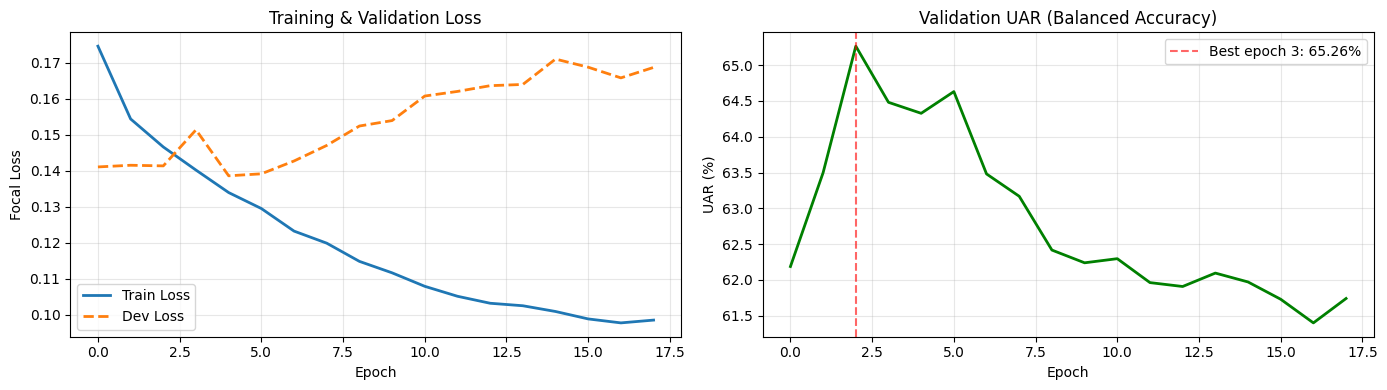

Best Dev UAR: 65.26%


In [ ]:
# ==========================================================
# CELL 10 — Train Model
# ==========================================================
print("="*55)
print("Training  Transformer + Focal Loss on Breathiness Features") 
print("="*55)

trained_model, history = train_model(
    model, train_loader, eval_loader,
    criterion, optimizer, scheduler,
    epochs=100, patience=15
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history['train_loss'], label='Train Loss', lw=2)
axes[0].plot(history['val_loss'],   label='Dev Loss',   lw=2, ls='--')
axes[0].set(xlabel='Epoch', ylabel='Focal Loss', title='Training & Validation Loss')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(history['val_uar'], color='green', lw=2)
best_e = int(np.argmax(history['val_uar']))
axes[1].axvline(best_e, color='red', ls='--', alpha=0.6,
                label=f"Best epoch {best_e+1}: {max(history['val_uar']):.2f}%")
axes[1].set(xlabel='Epoch', ylabel='UAR (%)', title='Validation UAR (Balanced Accuracy)')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Best Dev UAR: {max(history['val_uar']):.2f}%")


Results on Eval(dev+test) set  [default threshold = 0.5]
  UAR (Balanced Accuracy) : 65.26%
  Recall [cold    ]      : 64.20%
  Recall [noncold ]      : 66.33%

Classification Report (default threshold):
              precision    recall  f1-score   support

        cold       0.17      0.64      0.27      1905
     noncold       0.94      0.66      0.78     17239

    accuracy                           0.66     19144
   macro avg       0.56      0.65      0.53     19144
weighted avg       0.87      0.66      0.73     19144

ROC AUC                       : 0.7190
Optimal threshold (Youden)    : 0.4895

With Youden threshold (0.490):
  UAR                         : 65.17%
  Recall [cold    ]          : 68.14%
  Recall [noncold ]          : 62.20%


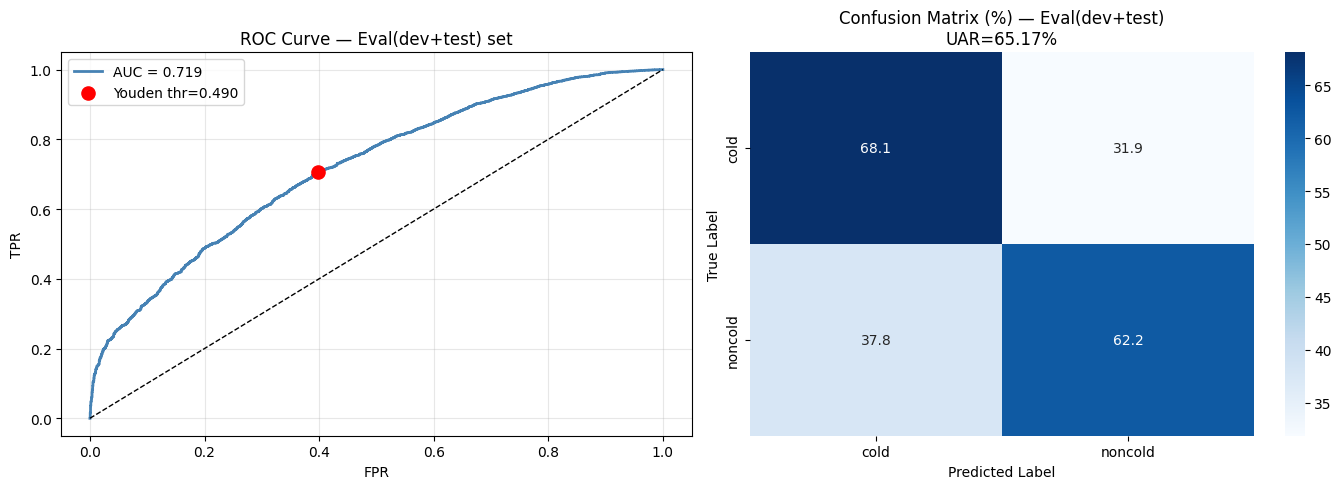

In [30]:
# ==========================================================
# CELL 11 — Evaluation: ROC, Youden's Index, Confusion Matrix, UAR
# ==========================================================
def full_evaluation(model, loader, split_name, le):
    """
    ROC curve, Youden's Index (optimal threshold), confusion matrix, UAR.
    Paper uses ROC + Youden's Index to determine classification threshold.
    """
    y_true, y_pred_def, y_probs = evaluate_loader(model, loader)

    # Recall per class at default threshold
    uar_def = compute_uar(y_true, y_pred_def)
    print(f"\n{'='*55}")
    print(f"Results on {split_name} set  [default threshold = 0.5]")
    print(f"{'='*55}")
    print(f"  UAR (Balanced Accuracy) : {uar_def:.2f}%")
    for i, cls in enumerate(le.classes_):
        mask = y_true==i
        if mask.sum()>0:
            rec = float(np.mean(y_pred_def[mask]==i))*100
            print(f"  Recall [{cls:8s}]      : {rec:.2f}%")
    print("\nClassification Report (default threshold):")
    print(classification_report(y_true, y_pred_def, target_names=le.classes_))

    # ROC + AUC
    fpr, tpr, thresholds = roc_curve(y_true, y_probs)
    roc_auc = auc(fpr, tpr)

    # Youden's Index: max(TPR - FPR)
    youden_idx = np.argmax(tpr - fpr)
    opt_thr    = thresholds[youden_idx]
    print(f"ROC AUC                       : {roc_auc:.4f}")
    print(f"Optimal threshold (Youden)    : {opt_thr:.4f}")

    # Re-predict with Youden threshold
    cold_idx   = list(le.classes_).index('cold')
    # y_probs = P(class index 1); invert if cold is index 0
    cold_probs = (1.0 - y_probs) if cold_idx == 0 else y_probs
    y_pred_y   = (cold_probs >= opt_thr).astype(int)
    if cold_idx == 0:
        y_pred_y = 1 - y_pred_y

    uar_y = compute_uar(y_true, y_pred_y)
    print(f"\nWith Youden threshold ({opt_thr:.3f}):")
    print(f"  UAR                         : {uar_y:.2f}%")
    for i, cls in enumerate(le.classes_):
        mask = y_true==i
        if mask.sum()>0:
            rec = float(np.mean(y_pred_y[mask]==i))*100
            print(f"  Recall [{cls:8s}]          : {rec:.2f}%")

    # ── Plots ────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(fpr, tpr, lw=2, color='steelblue',
                 label=f"AUC = {roc_auc:.3f}")
    axes[0].plot([0,1],[0,1],'k--',lw=1)
    axes[0].scatter(fpr[youden_idx], tpr[youden_idx],
                    color='red', s=90, zorder=5,
                    label=f"Youden thr={opt_thr:.3f}")
    axes[0].set(xlabel='FPR', ylabel='TPR',
                title=f"ROC Curve — {split_name} set")
    axes[0].legend(); axes[0].grid(alpha=0.3)

    cm     = confusion_matrix(y_true, y_pred_y)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
    sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Blues', ax=axes[1],
                xticklabels=le.classes_, yticklabels=le.classes_)
    axes[1].set(title=f"Confusion Matrix (%) — {split_name}\nUAR={uar_y:.2f}%",
                ylabel='True Label', xlabel='Predicted Label')

    plt.tight_layout()
    plt.savefig(f'results_{split_name.lower()}.png', dpi=150, bbox_inches='tight')
    plt.show()

    return {'uar_default': uar_def, 'uar_youden': uar_y, 'auc': roc_auc,
            'optimal_threshold': opt_thr,
            'y_true': y_true, 'y_pred': y_pred_y, 'y_probs': y_probs}


eval_results  = full_evaluation(trained_model, eval_loader,  'Eval(dev+test)', le)


Computing permutation importance (may take ~1 min)...


100%|██████████| 27/27 [01:16<00:00,  2.84s/it]


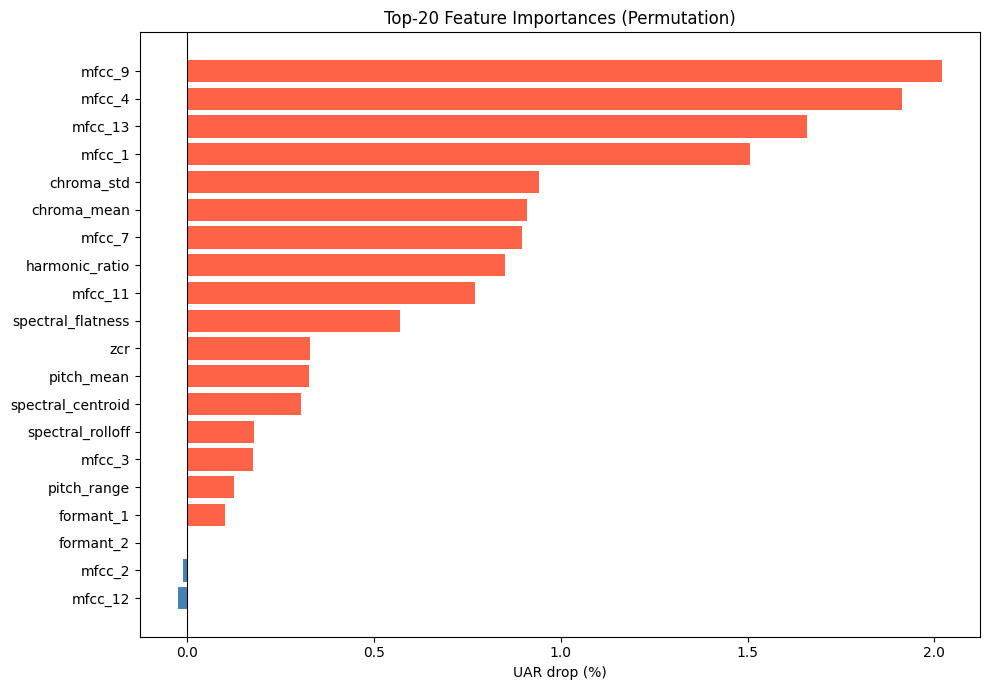


Top-10 most important features:
mfcc_9               2.020282
mfcc_4               1.912531
mfcc_13              1.658212
mfcc_1               1.506256
chroma_std           0.940884
chroma_mean          0.910563
mfcc_7               0.895581
harmonic_ratio       0.849131
mfcc_11              0.771201
spectral_flatness    0.569872
dtype: float64


In [31]:
# ==========================================================
# CELL 12 — Permutation Feature Importance
# ==========================================================
def permutation_feature_importance(model, X_s, y_enc, feat_names, n_repeats=3):
    loader    = DataLoader(TabularDataset(X_s, y_enc), batch_size=256, shuffle=False)
    base_uar  = compute_uar(y_enc, evaluate_loader(model, loader)[1])
    imp       = {}
    print("Computing permutation importance (may take ~1 min)...")
    for idx, name in enumerate(tqdm(feat_names)):
        drops = []
        for _ in range(n_repeats):
            Xp = X_s.copy(); np.random.shuffle(Xp[:, idx])
            p_uar = compute_uar(y_enc,
                evaluate_loader(model,
                    DataLoader(TabularDataset(Xp, y_enc), batch_size=256, shuffle=False)
                )[1])
            drops.append(base_uar - p_uar)
        imp[name] = float(np.mean(drops))
    series = pd.Series(imp).sort_values(ascending=False)
    top    = series.head(20)
    plt.figure(figsize=(10,7))
    colors = ['tomato' if v>0 else 'steelblue' for v in top.values]
    plt.barh(top.index[::-1], top.values[::-1], color=colors[::-1])
    plt.axvline(0, color='black', lw=0.8)
    plt.xlabel('UAR drop (%)'); plt.title('Top-20 Feature Importances (Permutation)')
    plt.tight_layout()
    plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
    plt.show()
    return series

feat_imp = permutation_feature_importance(
    trained_model, X_eval_s, y_eval_enc, feature_names, n_repeats=3)
print("\nTop-10 most important features:")
print(feat_imp.head(10))

In [32]:
# ==========================================================
# CELL 13 — Save Model & Artefacts
# ==========================================================
SAVE_DIR = './saved_model'; os.makedirs(SAVE_DIR, exist_ok=True)

torch.save({
    'model_state_dict': trained_model.state_dict(),
    'input_dim'       : input_dim,
    'num_classes'     : num_classes,
    'feature_names'   : feature_names,
    'eval_uar'         : eval_results['uar_youden'],
    'opt_threshold'   : eval_results['optimal_threshold'],
}, f"{SAVE_DIR}/cold_detection_transformer.pth")

joblib.dump(scaler, f"{SAVE_DIR}/scaler.pkl")
joblib.dump(le,     f"{SAVE_DIR}/label_encoder.pkl")
joblib.dump(feat_imp, f"{SAVE_DIR}/feature_importance.pkl")
print(f"All artefacts saved to {SAVE_DIR}/")

All artefacts saved to ./saved_model/


In [33]:
# ==========================================================
# CELL 14 — Prediction Function for New Audio
# ==========================================================
def predict_cold(audio_path: str) -> dict:
    """Predict cold/noncold for a new audio file."""
    feats = BreathinessFeatureExtractor(sr=16000).extract_all_features(audio_path)
    if feats is None:
        return {'error': 'Feature extraction failed'}
    vec   = np.array([[feats.get(k, 0.0) for k in feature_names]])
    vec_s = scaler.transform(vec)
    trained_model.eval()
    with torch.no_grad():
        logits = trained_model(torch.FloatTensor(vec_s).to(device))
        probs  = torch.softmax(logits, dim=1).cpu().numpy()[0]
    cold_idx  = list(le.classes_).index('cold')
    cold_prob = float(probs[cold_idx])
    opt_thr   = eval_results.get('optimal_threshold', 0.5)
    pred      = 'cold' if cold_prob >= opt_thr else 'noncold'
    return {
        'predicted_class'      : pred,
        'cold_probability'     : round(cold_prob, 4),
        'optimal_threshold'    : round(opt_thr, 4),
        'all_probs'            : dict(zip(le.classes_, probs.round(4))),
    }

# ── Example (uncomment to use) ────────────────────────────────
# result = predict_cold(r"path/to/audio.wav")
# print(result)

In [36]:
# ==========================================================
# CELL 15 — Final Summary
# ==========================================================
print("\n" + "="*62)
print("     FINAL RESULTS SUMMARY")
print("="*62)
print(f"{'Metric':<38}{'Develop':>12}{'Test':>12}")
print("-"*62)

rows = [
    ('UAR % (Youden threshold)',   'uar_youden',  ':.2f'),
    ('UAR % (default thr=0.5)',    'uar_default', ':.2f'),
    ('ROC AUC',                    'auc',         ':.4f'),
]
for label, key, fmt in rows:
    d = eval_results[key]; t = eval_results[key]
    if 'UAR' in label:
        print(f"  {label:<36}{d:>11.2f}%{t:>11.2f}%")
    else:
        print(f"  {label:<36}{d:>12.4f}{t:>12.4f}")

print("-"*62)
for cls in le.classes_:
    i = list(le.classes_).index(cls)
    for name, res in [('Dev', eval_results), ('Test', eval_results)]:
        m = res['y_true']==i
        if m.sum()>0:
            rec = float(np.mean(res['y_pred'][m]==i))*100
            print(f"  Recall [{cls:8s}] {name:4s}          {rec:>11.2f}%")

print("="*62)
print(f"\n  Paper targets:")
print(f"    Dev  UAR = 69.55%   Dev  AUC = 0.760")
print(f"    Test UAR = 70.48%   Test AUC = 0.769")
print(f"\n  Feature dimension  : {X_train.shape[1]}")
print(f"  Train (after SMOTE): {len(X_train_sm)}")
print(f"  Test samples       : {len(X_test)}")
print(f"  Architecture       : Transformer (2L, 8H, d=256, dropout=0.4)")
print(f"  Loss               : Focal Loss (α=1, γ=2)")
print("="*62)


     FINAL RESULTS SUMMARY
Metric                                     Develop        Test
--------------------------------------------------------------
  UAR % (Youden threshold)                  65.17%      65.17%
  UAR % (default thr=0.5)                   65.26%      65.26%
  ROC AUC                                   0.7190      0.7190
--------------------------------------------------------------
  Recall [cold    ] Dev                 68.14%
  Recall [cold    ] Test                68.14%
  Recall [noncold ] Dev                 62.20%
  Recall [noncold ] Test                62.20%

  Paper targets:
    Dev  UAR = 69.55%   Dev  AUC = 0.760
    Test UAR = 70.48%   Test AUC = 0.769

  Feature dimension  : 27
  Train (after SMOTE): 17064
  Test samples       : 9549
  Architecture       : Transformer (2L, 8H, d=256, dropout=0.4)
  Loss               : Focal Loss (α=1, γ=2)
